In [1]:
!pip install -q torch onnx onnxruntime fastapi pillow python-multipart httpx scikit-learn matplotlib

import io, time, torch, onnx
import torch.nn as nn
import numpy as np
import onnxruntime as ort
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from torch.utils.data import TensorDataset, DataLoader
from fastapi import FastAPI, UploadFile, File
from fastapi.testclient import TestClient

# Load & split 8x8 digits dataset
digits = load_digits()
X = digits.images.astype(np.float32) / 16.0
y = digits.target.astype(np.int64)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

X_train, y_train = torch.tensor(X_train[:1000]).unsqueeze(1), torch.tensor(y_train[:1000])
X_test, y_test = torch.tensor(X_test).unsqueeze(1), torch.tensor(y_test)
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=32, shuffle=True)

# Define & train CNN
class VisionModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Conv2d(1, 8, 3), nn.ReLU(), nn.Flatten(), nn.Linear(8 * 6 * 6, 10))
    def forward(self, x):
        return self.net(x)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = VisionModel().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
criterion = nn.CrossEntropyLoss()

epochs = 12
loss_hist, acc_hist = [], []

for epoch in range(epochs):
    model.train()
    total_loss, correct = 0, 0
    for imgs, lbls in train_loader:
        imgs, lbls = imgs.to(device), lbls.to(device)
        optimizer.zero_grad()
        out = model(imgs)
        loss = criterion(out, lbls)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
        correct += (out.argmax(1) == lbls).sum().item()
    loss_hist.append(total_loss / len(train_loader))
    acc_hist.append(100 * correct / len(X_train))
    print(f"Epoch {epoch+1:02d} | Loss: {loss_hist[-1]:.4f} | Acc: {acc_hist[-1]:.2f}%")


Epoch 01 | Loss: 2.1718 | Acc: 36.30%
Epoch 02 | Loss: 1.7672 | Acc: 69.90%
Epoch 03 | Loss: 1.2562 | Acc: 88.20%
Epoch 04 | Loss: 0.8546 | Acc: 89.70%
Epoch 05 | Loss: 0.6032 | Acc: 91.40%
Epoch 06 | Loss: 0.4666 | Acc: 92.40%
Epoch 07 | Loss: 0.3869 | Acc: 93.00%
Epoch 08 | Loss: 0.3294 | Acc: 93.30%
Epoch 09 | Loss: 0.3003 | Acc: 95.00%
Epoch 10 | Loss: 0.2623 | Acc: 94.30%
Epoch 11 | Loss: 0.2372 | Acc: 95.50%
Epoch 12 | Loss: 0.2201 | Acc: 95.30%


In [2]:
model.eval()
torch.onnx.export(
    model, torch.randn(1, 1, 8, 8).to(device), "vision_model.onnx",
    input_names=["input"], output_names=["output"], opset_version=17, dynamo=False
)
onnx.checker.check_model(onnx.load("vision_model.onnx"))

session = ort.InferenceSession("vision_model.onnx")
first = 0
input_name = session.get_inputs()[first].name
output_name = session.get_outputs()[first].name
print("ONNX Model Loaded:", input_name, "->", output_name)


/tmp/ipykernel_505/4123264081.py:2: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


ONNX Model Loaded: input -> output


In [4]:
app = FastAPI()

@app.get("/")
def home():
    return {"message": "VisionPort API Running"}

@app.post("/predict")
async def predict(file: UploadFile = File(...)):
    print("\n===== INFERENCE REQUEST TRACE =====")

    # 1. API INPUT
    image_bytes = await file.read()
    print(f"1. API INPUT      -> File: {file.filename} ({len(image_bytes)} bytes)")

    # 2. PREPROCESSING
    image = Image.open(io.BytesIO(image_bytes)).convert("L").resize((8, 8))
    data = (np.array(image).astype(np.float32) / 255.0).reshape(1, 1, 8, 8)
    print(f"2. PREPROCESSING  -> Grayscale, 8x8, Normalized tensor {data.shape}")

    # 3. MODEL EXECUTION
    start = time.time()
    outputs = session.run([output_name], {input_name: data})
    latency_ms = round((time.time() - start) * 1000, 2)
    first = 0
    digit = int(np.argmax(outputs[first]))
    print(f"3. MODEL EXEC     -> Predicted Digit: {digit} | Latency: {latency_ms} ms")

    # 4. API RESPONSE
    res_body = {
        "filename": file.filename,
        "prediction": digit,
        "inference_time_ms": latency_ms,
        "status": "success"
    }
    print(f"4. API RESPONSE   -> {res_body}")
    return res_body



===== INFERENCE REQUEST TRACE =====
1. API INPUT      -> File: test_digit.png (119 bytes)
2. PREPROCESSING  -> Grayscale, 8x8, Normalized tensor (1, 1, 8, 8)
3. MODEL EXEC     -> Predicted Digit: 5 | Latency: 0.28 ms
4. API RESPONSE   -> {'filename': 'test_digit.png', 'prediction': 5, 'inference_time_ms': 0.28, 'status': 'success'}

Actual Digit: 5 | Predicted Digit: 5 | Status: 200


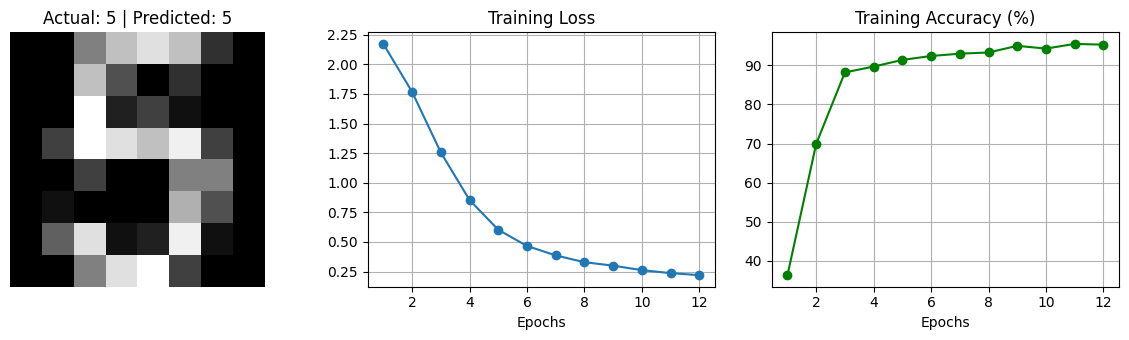

In [5]:
client = TestClient(app)

# Pick first test image
idx = 0
test_img = X_test[idx].squeeze().numpy()
actual = int(y_test[idx])

buf = io.BytesIO()
Image.fromarray((test_img * 255).astype(np.uint8)).save(buf, format="PNG")

# Send POST request to /predict
res = client.post("/predict", files={"file": ("test_digit.png", buf.getvalue(), "image/png")})
pred = res.json()["prediction"]
print(f"\nActual Digit: {actual} | Predicted Digit: {pred} | Status: {res.status_code}")

# Plot Digit + Loss & Accuracy Curves
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
p0, p1, p2 = axes

p0.imshow(test_img, cmap="gray")
p0.set_title(f"Actual: {actual} | Predicted: {pred}")
p0.axis("off")

p1.plot(range(1, epochs + 1), loss_hist, marker="o")
p1.set_title("Training Loss")
p1.set_xlabel("Epochs")
p1.grid(True)

p2.plot(range(1, epochs + 1), acc_hist, marker="o", color="green")
p2.set_title("Training Accuracy (%)")
p2.set_xlabel("Epochs")
p2.grid(True)

plt.tight_layout()
plt.show()

